# Arabica: which preprocessing, with which model?

**Already applied to arabica so far:** every arabica model used the robusta recipe, **absorbance + offset**
(log10(1/R), then each spectrum's own mean subtracted) on 1000–2450 nm. EMSC + PLSR added EMSC on top of that.
The preprocessing was never re-chosen for arabica. This notebook does that.

**Grid:** 9 preprocessings × 5 linear models = 45 combinations, each through the same nested leave-one-session-out
as the final notebooks (trimming and super-patches rebuilt inside each round from the preprocessed patches, inner
leave-one-concentration-out with the one-standard-error rule, error per dish on the held-out session).

- **Preprocessings:** the 8 options tested on robusta (`04_checks/preprocessing_check_nested_loso.py`, same
  settings: Savitzky–Golay window 15, order 2; MSC reference from the training sessions only), plus **EMSC**
  (on absorbance + offset, basis from the training sessions only).
- **Models:** PLSR, PCR, Ridge, ElasticNet, linear SVR, with the arabica notebook's grids. Random Forest, Gradient
  Boosting and RBF-SVR are left out: they were 4–9× worse on both coffees.

**Reading the result honestly:** picking the best of 45 on the same three test sessions flatters the winner. A
combination only counts as a real improvement on EMSC + PLSR (the current best, 0.78 %) if the paired bootstrap says
*better* **and** it is better in at least two of the three sessions.

## 1. Building blocks, executed from the arabica notebook (no changes)

In [1]:
import os
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from scipy.signal import savgol_filter
from pathlib import Path

SRC = Path(os.environ.get("COFFEE_DATA", ".")) / "arabica_chicory_nested_loso.ipynb"
nb = json.loads(SRC.read_text())
cell = lambda i: "".join(nb["cells"][i]["source"])
ns = {}
exec(cell(2), ns)          # setup
exec(cell(4), ns)          # data: AB100 + 5-50 %, absorbance + offset -> DATA, COLS, Z, SESSION, GROUP, Y
exec(cell(6), ns)          # units(), make(), GRIDS, tune(), predict(), score()
DATA, COLS, SESSION, WL = ns["DATA"], ns["COLS"], ns["SESSION"], ns["WL"]
OUT = ns["BASE"] / "arabica_preprocessing"
OUT.mkdir(exist_ok=True, parents=True)
R = np.clip(DATA[COLS].values.astype(float), 1e-3, None)
print(len(DATA), "patches,", DATA.group.nunique(), "dishes,", len(WL), "bands")

4950 patches | 33 plates | 266 bands (1001-2446 nm)
                   chicory  plates  patches
session label                              
1       AB100          0.0       3      450
2       AB[50:50]     50.0       3      450
        AB[60:40]     40.0       3      450
        AB[70:30]     30.0       3      450
        AB[80:20]     20.0       3      450
        AB[90:10]     10.0       3      450
3       AB[55:45]     45.0       3      450
        AB[65:35]     35.0       3      450
        AB[75:25]     25.0       3      450
        AB[85:15]     15.0       3      450
        AB[95:5]       5.0       3      450
4950 patches, 33 dishes, 266 bands


## 2. The nine preprocessings and five models

In [2]:
def snv(A): return (A - A.mean(-1, keepdims=True)) / (A.std(-1, keepdims=True) + 1e-12)
def msc(A, ref):
    M = np.column_stack([ref, np.ones_like(ref)]); c = np.linalg.pinv(M) @ A.T
    return (A - c[1][:, None]) / np.where(np.abs(c[0]) > 1e-9, c[0], 1e-9)[:, None]
sg   = lambda A, d: savgol_filter(A, 15, 2, deriv=d, axis=1)
absb = lambda A: np.log10(1.0 / A)
off  = lambda A: A - A.mean(-1, keepdims=True)

PREP = {"absorbance + offset (current)": lambda A, tr: off(absb(A)),
        "absorbance + offset + EMSC":    lambda A, tr: off(absb(A)),      # EMSC applied after super-patching
        "absorbance":                    lambda A, tr: absb(A),
        "raw reflectance":               lambda A, tr: A,
        "SNV":                           lambda A, tr: snv(A),
        "MSC":                           lambda A, tr: msc(A, A[tr].mean(0)),
        "absorbance + SG1":              lambda A, tr: sg(absb(A), 1),
        "SG1":                           lambda A, tr: sg(A, 1),
        "SG2":                           lambda A, tr: sg(A, 2)}
MODELS = ["PLSR", "PCR", "Ridge", "ElasticNet", "SVR (linear)"]

LAM = np.linspace(-1, 1, len(WL))
def emsc(ZU, tr, y):
    m = ZU[tr].mean(0); yc = y[tr] - y[tr].mean()
    k = yc @ (ZU[tr] - m) / (yc @ yc)
    B = np.column_stack([np.ones_like(LAM), m, k, LAM, LAM ** 2])
    a, b, h, d, e = np.linalg.lstsq(B, ZU.T, rcond=None)[0]
    return (ZU - a[:, None] - np.outer(d, LAM) - np.outer(e, LAM ** 2)) / b[:, None]

## 3. Nested leave-one-session-out for all 45 combinations (takes several minutes)

In [3]:
rows, dish = [], {}
for pname, f in PREP.items():
    for held in (1, 2, 3):
        train = [s for s in (1, 2, 3) if s != held]
        ns["Z"] = f(R, np.isin(SESSION, train)); ns["_UNITS"].clear()
        ZU, UM = ns["units"](train)
        us, y, g = UM.session.to_numpy(), UM.chicory_pct.to_numpy(float), UM.group.to_numpy()
        tr, te = np.isin(us, train), us == held
        if "EMSC" in pname:
            ZU = emsc(ZU, tr, y)
        for m in MODELS:
            prm, _ = ns["tune"](m, ZU[tr], y[tr], g[tr])
            p = ns["predict"](ns["make"](m, prm).fit(ZU[tr], y[tr]), ZU[te])
            pl = pd.DataFrame(dict(g=g[te], y=y[te], p=p)).groupby("g")[["y", "p"]].mean()
            dish[(pname, m, held)] = pl
            rows.append(dict(prep=pname, model=m, held=held, param=prm,
                             rmsep=float(np.sqrt(((pl.p - pl.y) ** 2).mean())), bias=float((pl.p - pl.y).mean())))
    print("done:", pname, flush=True)
T = pd.DataFrame(rows)
T.to_csv(OUT / "all_combinations_per_session.csv", index=False)

chk = T[(T.prep == "absorbance + offset (current)")].pivot(index="model", columns="held", values="rmsep").round(2)
print("\ncheck, absorbance + offset (must match the arabica notebook: PLSR 4.38/1.61/1.83, SVR 0.37/1.29/1.12):")
print(chk.to_string())
print("check, EMSC + PLSR (must be 0.38/1.28/0.68):",
      T[(T.prep == "absorbance + offset + EMSC") & (T.model == "PLSR")].rmsep.round(2).tolist())

done: absorbance + offset (current)


done: absorbance + offset + EMSC


done: absorbance


done: raw reflectance


done: SNV


done: MSC


done: absorbance + SG1


done: SG1


done: SG2



check, absorbance + offset (must match the arabica notebook: PLSR 4.38/1.61/1.83, SVR 0.37/1.29/1.12):
held             1     2     3
model                         
ElasticNet    1.58  1.17  0.93
PCR           9.71  1.31  1.41
PLSR          4.38  1.61  1.83
Ridge         2.02  1.34  1.30
SVR (linear)  0.37  1.29  1.12
check, EMSC + PLSR (must be 0.38/1.28/0.68): [0.38, 1.28, 0.68]


## 4. Results

Mean error per dish over the three held-out sessions, for every combination. The verdict compares each combination
with the current best, EMSC + PLSR, by the paired bootstrap (dishes resampled within each session).

In [4]:
REF = ("absorbance + offset + EMSC", "PLSR")
rng = np.random.default_rng(0); B = 2000
def boot(key):
    d = np.zeros(B)
    for s in (1, 2, 3):
        a = dish[(*REF, s)]; b = dish[(*key, s)].loc[a.index]
        ea, eb = ((a.p - a.y) ** 2).to_numpy(), ((b.p - b.y) ** 2).to_numpy()
        ii = rng.integers(0, len(ea), size=(B, len(ea)))
        d += (np.sqrt(eb[ii].mean(1)) - np.sqrt(ea[ii].mean(1))) / 3
    return np.percentile(d, [2.5, 97.5])

S = T.groupby(["prep", "model"]).agg(mean=("rmsep", "mean"), sd=("rmsep", "std"), worst=("rmsep", "max"),
                                     max_bias=("bias", lambda v: v.abs().max())).reset_index()
per = T.pivot_table(index=["prep", "model"], columns="held", values="rmsep").rename(columns=lambda s: f"S{s}")
S = S.merge(per.reset_index(), on=["prep", "model"])
ref_s = S[(S.prep == REF[0]) & (S.model == REF[1])][["S1", "S2", "S3"]].to_numpy().ravel()
verd, ci, wins = [], [], []
for _, r in S.iterrows():
    w = int((r[["S1", "S2", "S3"]].to_numpy(float) < ref_s - 1e-9).sum())
    if (r.prep, r.model) == REF:
        verd.append("reference"); ci.append(""); wins.append(np.nan); continue
    lo, hi = boot((r.prep, r.model))
    v = "better" if hi < 0 else "worse" if lo > 0 else "tie"
    verd.append(v + (" (and better in ≥2 sessions)" if v == "better" and w >= 2 else ""))
    ci.append(f"{lo:+.2f} to {hi:+.2f}"); wins.append(w)
S["sessions_better_than_ref"], S["verdict_vs_EMSC+PLSR"], S["ci"] = wins, verd, ci
S = S.sort_values("mean").reset_index(drop=True)
S.to_csv(OUT / "all_combinations_summary.csv", index=False)
pd.set_option("display.width", 220)
print(S.head(15).round(2).to_string(index=False))

print("\nbest model for each preprocessing:")
best = S.loc[S.groupby("prep")["mean"].idxmin()].sort_values("mean")
print(best[["prep", "model", "S1", "S2", "S3", "mean", "verdict_vs_EMSC+PLSR"]].round(2).to_string(index=False))
print("\nbest preprocessing for each model:")
bm = S.loc[S.groupby("model")["mean"].idxmin()].sort_values("mean")
print(bm[["model", "prep", "S1", "S2", "S3", "mean", "verdict_vs_EMSC+PLSR"]].round(2).to_string(index=False))

                         prep        model  mean   sd  worst  max_bias   S1   S2   S3  sessions_better_than_ref verdict_vs_EMSC+PLSR             ci
   absorbance + offset + EMSC          PCR  0.75 0.57   1.38      0.17 0.28 1.38 0.58                       2.0                  tie -0.16 to +0.08
   absorbance + offset + EMSC         PLSR  0.78 0.46   1.28      0.39 0.38 1.28 0.68                       NaN            reference               
                          SG1        Ridge  0.84 0.54   1.38      0.70 0.30 1.38 0.84                       1.0                  tie -0.11 to +0.20
                          SG1         PLSR  0.86 0.40   1.29      0.60 0.50 1.29 0.78                       0.0                  tie -0.10 to +0.24
                          SG1   ElasticNet  0.90 0.36   1.24      0.49 0.52 1.24 0.94                       1.0                  tie -0.05 to +0.25
             absorbance + SG1   ElasticNet  0.91 0.62   1.39      0.75 0.20 1.39 1.14                       1.0 

## 5. Figure: the whole grid

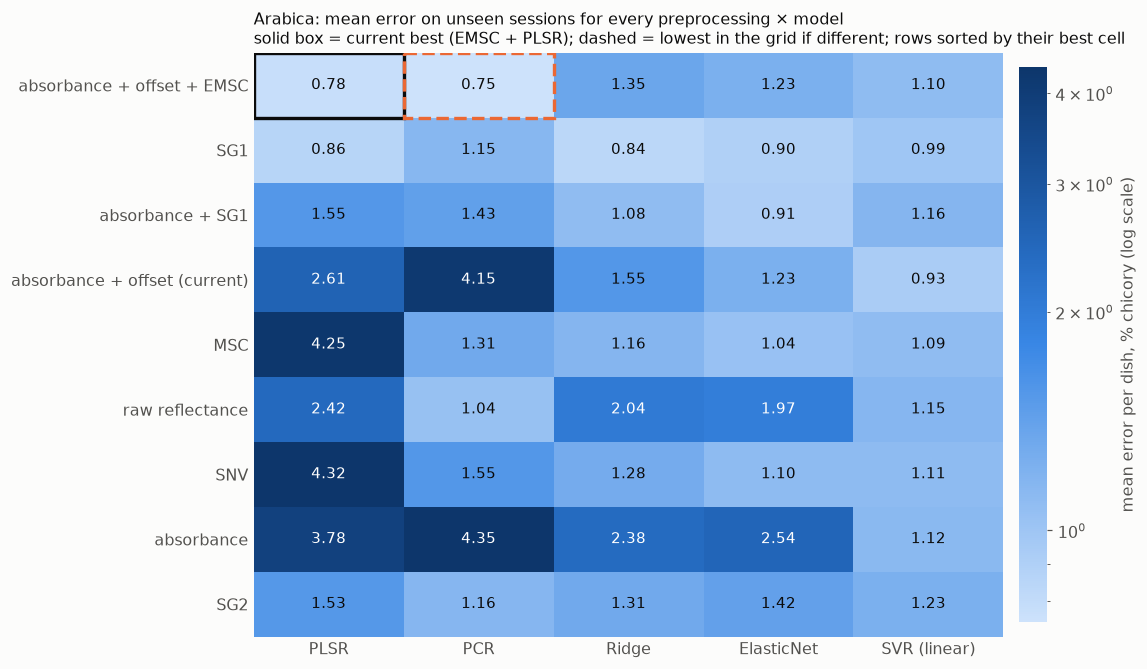

saved to /run/media/riyanvarghese/RIYAN HDD/coffee data/arabica_preprocessing


In [5]:
SEQ = LinearSegmentedColormap.from_list("blue_seq", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf",
                                                     "#184f95", "#0d366b"])
prep_order = S.groupby("prep")["mean"].min().sort_values().index.tolist()
M = S.pivot(index="prep", columns="model", values="mean").loc[prep_order, MODELS]
fig, ax = plt.subplots(figsize=(10.5, 6.2))
im = ax.imshow(M.to_numpy(), cmap=SEQ, norm=LogNorm(vmin=max(M.min().min(), .3), vmax=M.max().max()), aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.iat[i, j]
        dark = np.log(v / M.min().min()) > .55 * np.log(M.max().max() / M.min().min())
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9.5, color="white" if dark else "#0b0b0b")
r0, c0 = prep_order.index(REF[0]), MODELS.index(REF[1])
ax.add_patch(plt.Rectangle((c0 - .5, r0 - .5), 1, 1, fill=False, ec="#0b0b0b", lw=2.2))
bi = S.iloc[0]
if (bi.prep, bi.model) != REF:
    ax.add_patch(plt.Rectangle((MODELS.index(bi.model) - .5, prep_order.index(bi.prep) - .5), 1, 1,
                               fill=False, ec="#eb6834", lw=2.2, ls="--"))
ax.set_xticks(range(len(MODELS)), MODELS); ax.set_yticks(range(len(prep_order)), prep_order)
ax.tick_params(length=0); ax.grid(False)
for s_ in ax.spines.values(): s_.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=.035, pad=.02); cb.set_label("mean error per dish, % chicory (log scale)")
cb.outline.set_visible(False)
ax.set_title("Arabica: mean error on unseen sessions for every preprocessing × model\n"
             "solid box = current best (EMSC + PLSR); dashed = lowest in the grid if different; rows sorted by their best cell",
             loc="left", fontsize=10.5)
plt.tight_layout(); plt.savefig(OUT / "01_preprocessing_x_model.png", bbox_inches="tight"); plt.show()
print("saved to", OUT)